# Socios comerciales de Argentina
## ¿Quién ganó peso en las importaciones con el cambio de régimen frente al mercado externo?

- **Unidad de análisis:** país socio (país de origen de las importaciones) por año.
- **Período:** 2019–2025. Comparo 2019–2023 con 2024–2025.
- **Por qué importa:** desde 2024 cambió la política hacia el comercio exterior, con menos restricciones a las importaciones. Ver qué socios ganaron o perdieron peso ayuda a entender a qué mercados se abrió la economía argentina.

In [1]:
import pandas as pd  #importo la librería para trabajar con tablas

from config import PROCESADO  #la carpeta datos/procesado, de config.py

#leo la tabla que guardé al final del notebook 2
por_pais = pd.read_csv(
    PROCESADO / "importaciones_por_pais.csv",  # ruta del archivo
    dtype={"iso2": str},  #el código del país como texto
    keep_default_na=False,  #para que "NA" (Namibia) no se lea como dato faltante
)

print(por_pais.dtypes)  #compruebo los tipos: año entero, código texto, montos con decimales
por_pais.head()  #muestro las primeras filas

Año                int64
iso2                 str
CIF(USD)         float64
participacion    float64
dtype: object


,Año,iso2,CIF(USD),participacion
0,2019,AD,2.820360e+03,0.000006
1,2019,AE,1.860961e+08,0.383368
2,2019,AF,2.665620e+04,0.000055
3,2019,AG,7.798900e+02,0.000002
4,2019,AL,7.226068e+05,0.001489


In [2]:
por_pais["periodo"] = "2019-2023"
por_pais.loc[por_pais["Año"] >= 2024, "periodo"] = "2024-2025"

por_pais["periodo"].value_counts()

periodo
2019-2023    904
2024-2025    368
Name: count, dtype: int64

In [3]:
#armo una tabla con una fila por país y una columna por período

por_periodo = por_pais.pivot_table(
    index="iso2",          # una fila por país
    columns="periodo",     # una columna por período
    values="CIF(USD)",     # lo que pongo en las celdas
    aggfunc="sum",         # sumo los años de cada período
    fill_value=0,          # si un país no tuvo importaciones en un período, pongo 0
)

# Paso de dólares a participación: cada columna dividida por su total
por_periodo = por_periodo / por_periodo.sum() * 100

# Cuántos puntos porcentuales ganó o perdió cada país
por_periodo["cambio_pp"] = por_periodo["2024-2025"] - por_periodo["2019-2023"]

por_periodo.sort_values("cambio_pp", ascending=False).head(10)  # los 10 que más ganaron

periodo,2019-2023,2024-2025,cambio_pp
iso2,,,
BR,21.143331,24.303181,3.159850
CN,20.683625,21.959447,1.275823
PY,4.122589,4.653175,0.530587
TH,2.395090,2.842769,0.447679
JP,1.688380,1.981021,0.292641
NG,0.081852,0.229142,0.147289
MX,2.198219,2.334694,0.136475
CH,0.810664,0.941980,0.131316
MA,0.582581,0.713062,0.130481


In [4]:
assert ((por_periodo[["2019-2023", "2024-2025"]].sum() - 100).abs() < 0.001).all(), "Las participaciones no suman 100%"  # cada período suma 100%
assert abs(por_periodo["cambio_pp"].sum()) < 0.001, "Lo que ganan unos tiene que ser lo que pierden otros"  # los cambios suman cero

In [5]:
por_periodo.sort_values("cambio_pp", ascending=True).head(10)  #ordeno de menor a mayor cambio: arriba los que más perdieron

periodo,2019-2023,2024-2025,cambio_pp
iso2,,,
US,11.496763,9.475666,-2.021096
BO,2.237122,0.635551,-1.601571
SA,0.607311,0.140152,-0.467158
EG,0.525007,0.118826,-0.406181
NL,1.005415,0.626771,-0.378644
MY,0.576994,0.376865,-0.200129
TW,0.694630,0.495199,-0.199432
AE,0.546109,0.354548,-0.191561
QA,0.277968,0.101585,-0.176383


In [6]:
import geopandas as gpd  # librería para trabajar con mapas (es como pandas, pero con geometrías)

from config import GEO  # la carpeta datos/geo

mundo = gpd.read_file(GEO / "ne_110m_admin_0_countries.geojson")  # leo el mapa: una fila por país con su forma
mundo = mundo[["ISO_A2_EH", "NAME_ES", "geometry"]].rename(  # me quedo con 3 columnas y les cambio el nombre
    columns={"ISO_A2_EH": "iso2", "NAME_ES": "nombre"}  # código ISO, nombre en español y la forma del país
)

# Saco la Antártida y dos territorios sin código ISO propio (en el mapa figuran como "-99")
mundo = mundo[~mundo["iso2"].isin(["AQ", "-99"])]  # me quedo con las filas cuyo código NO está en esa lista

assert mundo["iso2"].is_unique, "Hay países repetidos en el mapa"  # cada país una sola vez, para que el merge no duplique
print(len(mundo), "países en el mapa")  # 174 países

174 países en el mapa


In [7]:
#saco a Argentina: es el país que importa, no un socio (son reimportaciones)
datos_mapa = por_periodo.drop(index="AR").reset_index()  # borro la fila de Argentina y paso iso2 de índice a columna

filas_antes = len(mundo)  # guardo cuántos países tiene el mapa antes de unir (174)
mapa = mundo.merge(datos_mapa, on="iso2", how="outer", validate="1:1", indicator=True)  # uno el mapa con mis datos por código ISO
print(mapa["_merge"].value_counts())  # cuento cuántos países están en las dos tablas y cuántos en una sola

_merge
both          168
right_only     37
left_only       6
Name: count, dtype: int64


El merge da 168 países en las dos tablas. 37 países de los datos no están en el mapa porque son muy chicos para esta escala (por ejemplo Singapur, Hong Kong, Malta y Bahréin); suman 0,32% de las importaciones en 2019–2023 y 0,22% en 2024–2025, así que los dejo afuera del mapa. 6 países del mapa no tienen datos: Argentina, que saqué porque es el país que importa, y países a los que no se les compró nada.

In [8]:
sin_mapa = mapa[mapa["_merge"] == "right_only"]  # filtro los países que están en mis datos pero no en el mapa
print("Países sin geometría:", sin_mapa["iso2"].tolist())  # muestro sus códigos como lista
print("Peso en las importaciones (%):")
print(sin_mapa[["2019-2023", "2024-2025"]].sum().round(2))  # sumo cuánto pesan en cada período

mapa = mapa[mapa["_merge"] != "right_only"].drop(columns="_merge")  # me quedo con los países que tienen forma en el mapa y borro _merge
assert len(mapa) == filas_antes, "El merge cambió la cantidad de países del mapa"  # vuelvo a tener los 174 países del mapa

Países sin geometría: ['AD', 'AG', 'AW', 'BB', 'BH', 'BQ', 'CV', 'CW', 'DM', 'GD', 'GI', 'HK', 'KM', 'KN', 'LC', 'LI', 'MC', 'MH', 'MO', 'MP', 'MT', 'MU', 'MV', 'NR', 'PN', 'PW', 'SC', 'SG', 'SM', 'ST', 'SX', 'TO', 'TV', 'VA', 'VC', 'VG', 'WS']
Peso en las importaciones (%):
2019-2023    0.32
2024-2025    0.22
dtype: float64


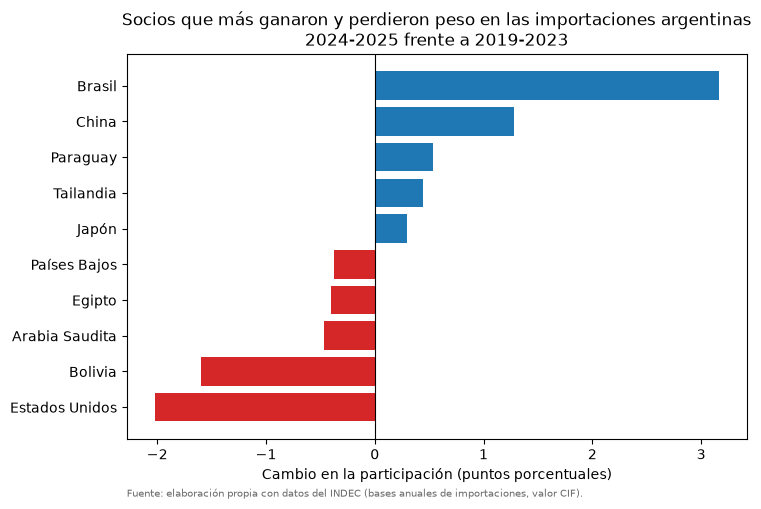

In [9]:
import matplotlib.pyplot as plt  # librería para hacer gráficos

# Uso la tabla del mapa porque ya tiene los nombres en español
cambios = mapa.dropna(subset=["cambio_pp"]).set_index("nombre")["cambio_pp"].sort_values()  # cambio de cada país, de menor a mayor
extremos = pd.concat([cambios.head(5), cambios.tail(5)])  # los 5 que más perdieron y los 5 que más ganaron

colores = ["tab:red" if valor < 0 else "tab:blue" for valor in extremos]  # rojo si perdió, azul si ganó

fig, ax = plt.subplots(figsize=(8, 5))  # creo la figura (fig) y el espacio del gráfico (ax), de 8 x 5 pulgadas
ax.barh(extremos.index, extremos, color=colores)  # barras horizontales: países en el eje vertical, cambio en el horizontal
ax.axvline(0, color="black", linewidth=0.8)  # línea vertical en el cero, para separar ganadores de perdedores
ax.set_title("Socios que más ganaron y perdieron peso en las importaciones argentinas\n2024-2025 frente a 2019-2023")  # título; \n es un salto de línea
ax.set_xlabel("Cambio en la participación (puntos porcentuales)")  # nombre del eje horizontal, con la unidad
ax.annotate(  # agrego un texto chico abajo con la fuente
    "Fuente: elaboración propia con datos del INDEC (bases anuales de importaciones, valor CIF).",
    xy=(0, -0.15), xycoords="axes fraction", fontsize=7, color="dimgrey",  # posición (abajo a la izquierda), tamaño y color
)
fig.savefig("figuras/cambio_participacion.png", dpi=150, bbox_inches="tight")  # guardo el gráfico como imagen en la carpeta figuras
plt.show()  # muestro el gráfico en el notebook

Brasil fue el socio que más ganó participación en las importaciones (+3,2 puntos porcentuales) y China el segundo (+1,3). Del otro lado, Estados Unidos (−2,0) y Bolivia (−1,6) fueron los que más perdieron. En 2024–2025 las importaciones se concentraron más en los dos socios principales.

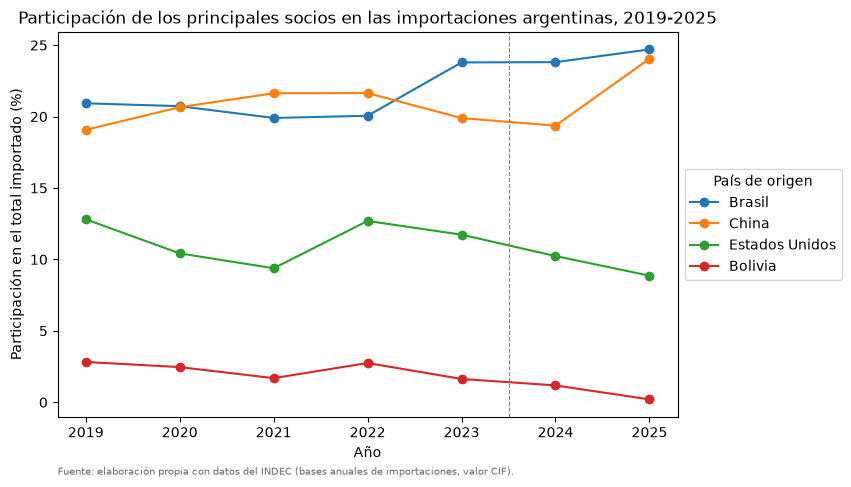

In [10]:
anual = por_pais.pivot_table(index="Año", columns="iso2", values="participacion")  # tabla con años en filas, países en columnas y la participación adentro
socios = {"BR": "Brasil", "CN": "China", "US": "Estados Unidos", "BO": "Bolivia"}  # los países que quiero mostrar: código y nombre
anual = anual[list(socios)].rename(columns=socios)  # me quedo con esas 4 columnas y les pongo el nombre en español

fig, ax = plt.subplots(figsize=(8, 5))  # creo la figura y el área del gráfico
anual.plot(ax=ax, marker="o")  # una línea por país; marker="o" pone un punto en cada año
ax.axvline(2023.5, color="grey", linestyle="--", linewidth=0.8)  # línea gris punteada entre 2023 y 2024: separa los dos períodos
ax.set_title("Participación de los principales socios en las importaciones argentinas, 2019-2025")  # título
ax.set_xlabel("Año")  # nombre del eje horizontal
ax.set_ylabel("Participación en el total importado (%)")  # nombre del eje vertical, con la unidad
ax.legend(title="País de origen", loc="center left", bbox_to_anchor=(1, 0.5))  # leyenda afuera, a la derecha del gráfico
ax.annotate(  # la fuente, abajo
    "Fuente: elaboración propia con datos del INDEC (bases anuales de importaciones, valor CIF).",
    xy=(0, -0.15), xycoords="axes fraction", fontsize=7, color="dimgrey",
)
fig.savefig("figuras/participacion_anual.png", dpi=150, bbox_inches="tight")  # guardo la imagen
plt.show()  # muestro el gráfico

El gráfico anual muestra que los cambios no empezaron todos en 2024, Brasil ya había subido en 2023, China recién salta en 2025, Estados Unidos baja desde 2022 y Bolivia cae durante todo el período. Comparar solo los dos períodos esconde en qué momento ocurrió cada cambio.

In [11]:
# Función de la clase 6 (sección 2.8): mapa coroplético con la lista de control mínima
def mapa_coropletico(gdf, columna, titulo, etiqueta, fuente, ax=None, crs="ESRI:102033", **kwargs):  # recibe el mapa, qué columna pintar, textos, dónde dibujar y la proyección
    """Dibuja un mapa coroplético con la lista de control mínima.
    ...
    """
    if ax is None:  # si no me dicen dónde dibujar...
        _, ax = plt.subplots(figsize=(6, 8))  # ...creo un gráfico nuevo
    opciones = {  # diccionario con las opciones de dibujo por defecto
        "cmap": "viridis", "edgecolor": "white", "linewidth": 0.3, "legend": True,  # paleta de colores, borde blanco fino entre países, con leyenda
        "missing_kwds": {"color": "lightgrey", "hatch": "///", "label": "sin dato"},  # los países sin dato: gris claro rayado, con el rótulo "sin dato"
    }
    if "scheme" in kwargs:  # si me pasaron un esquema de clases (cortes)...
        opciones["legend_kwds"] = {"title": etiqueta, "loc": "lower right", "fontsize": 8}  # ...leyenda por clases, abajo a la derecha
    else:  # si no...
        opciones["legend_kwds"] = {"label": etiqueta, "shrink": 0.6}  # ...barra de colores continua
    opciones.update(kwargs)  # agrego (o piso) con las opciones que me pasen al llamar la función
    gdf.to_crs(crs).plot(column=columna, ax=ax, **opciones)  # cambio la proyección del mapa y lo pinto según la columna
    ax.set_title(titulo, fontsize=12)  # título
    ax.set_axis_off()  # saco los ejes con números: en un mapa no hacen falta
    ax.annotate(fuente, xy=(0, -0.02), xycoords="axes fraction", fontsize=7, va="top", color="dimgrey")  # la fuente, abajo
    return ax  # devuelvo el área del gráfico

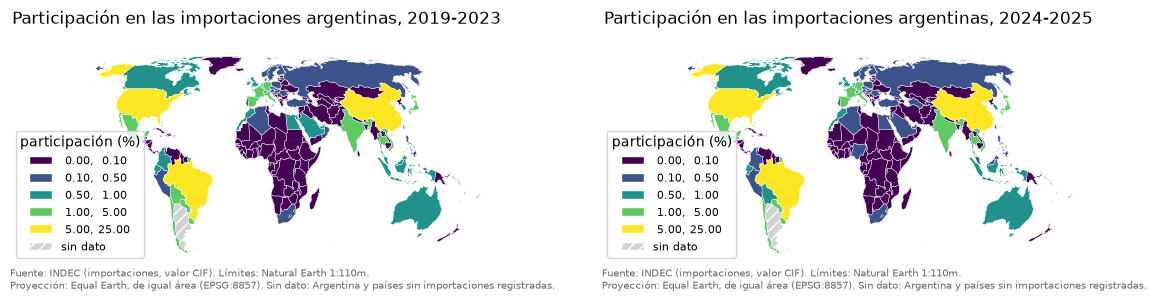

In [13]:
cortes = [0.1, 0.5, 1, 5, 25]  # los mismos límites de clase para los dos mapas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # una figura con 2 gráficos lado a lado (1 fila, 2 columnas)
for ax, periodo in zip(axes, ["2019-2023", "2024-2025"]):  # recorro a la vez los dos espacios y los dos períodos
    mapa_coropletico(  # llamo a la función de la clase
        mapa, periodo,  # el mapa y la columna a pintar: la participación de ese período
        titulo=f"Participación en las importaciones argentinas, {periodo}",  # título con el período
        legend_kwds={"title": "participación (%)", "loc": "lower left", "fontsize": 8},  # leyenda abajo a la izquierda, para no tapar Australia
        etiqueta="participación (%)",  # qué mide y en qué unidad
        fuente=(  # fuente y proyección, en dos líneas
            "Fuente: INDEC (importaciones, valor CIF). Límites: Natural Earth 1:110m.\n"
            "Proyección: Equal Earth, de igual área (EPSG:8857). Sin dato: Argentina y países sin importaciones registradas."
        ),
        ax=ax,  # dibujo en el espacio que toca en esta vuelta
        crs="EPSG:8857",  # proyección Equal Earth, de igual área, para el mundo entero
        scheme="user_defined",  # clases con cortes elegidos por mí
        classification_kwds={"bins": cortes},  # los cortes: los mismos en los dos mapas
    )
fig.savefig("figuras/mapa_participacion.png", dpi=150, bbox_inches="tight")  # guardo la imagen
plt.show()  # muestro los mapas

**Qué mide:** la participación de cada país en el valor importado por Argentina (CIF, en %), en 2019–2023 y en 2024–2025.

**Con qué geometrías:** los países de Natural Earth, escala 1:110 millones.

**En qué sistema de coordenadas:** Equal Earth (EPSG:8857), una proyección de igual área para todo el mundo. No usé la de la clase (ESRI:102033) porque es para Sudamérica.

**Con qué escala y colores:** cinco clases con cortes fijos (0,1 / 0,5 / 1 / 5 / 25 %), iguales en los dos mapas para poder compararlos, con la paleta viridis. Los cortes son desiguales porque la mayoría de los países tiene menos de 1% y solo dos superan el 20%.

**Qué falta:** Argentina (es el país que importa); los países a los que no se les compró nada; 37 países muy chicos que no aparecen a esta escala (por ejemplo Singapur, Hong Kong y Malta), que suman 0,32% de las importaciones en 2019–2023 y 0,22% en 2024–2025; y las entradas que no son países (“Confidencial”, “Indeterminado”), entre 0,9% y 1,6% de cada año.

### Qué verifiqué y qué no

Controles con *assert*:

1. En cada año, la cantidad de filas y el total CIF coinciden con el archivo de control que publica el INDEC.
2. No hay filas repetidas por año, producto y país, ni montos negativos.
3. Todos los códigos de país de la base están en el nomenclador, y cada código aparece una sola vez.
4. Los 490.822 códigos NCM tienen 8 dígitos.
5. Los merges no agregaron ni perdieron filas.
6. Las participaciones suman 100% en cada año y en cada período, y los cambios suman cero.

Controles mirando:

1. Los nombres de las columnas cambian entre 2021 (u$s) y 2022 (USD); los unifiqué con código.
2. Revisé la lista de entradas que no son países (33 en el nomenclador) y su peso en cada año.
3. Los principales socios de 2024 (Brasil, China y Estados Unidos, en ese orden) coinciden con lo que informó la prensa con datos del INDEC.

# Conclusiones

### ¿Qué responden los datos?

Entre 2019–2023 y 2024–2025, los socios que más ganaron peso en las importaciones argentinas fueron Brasil, que pasó de 21,1% a 24,3% (+3,2 puntos), y China, que pasó de 20,7% a 22,0% (+1,3). Entre los dos pasaron de concentrar el 41,8% de las importaciones a concentrar el 46,3%. Del otro lado, los que más peso perdieron fueron Estados Unidos, de 11,5% a 9,5% (−2,0 puntos), y Bolivia, de 2,2% a 0,6% (−1,6). Después aparecen Arabia Saudita, Egipto, Países Bajos, Qatar y Emiratos Árabes, con caídas más chicas. O sea que, en los años de menos restricciones a las importaciones, las compras no se diversificaron hacia nuevos socios, sino que se concentraron más en los dos principales. 

Algo interessnte, no todos los cambios empiezan en 2024. Brasil ya había ganado peso en 2023, China salta recién en 2025, Estados Unidos cae desde 2022 y Bolivia pierde peso durante todo el período. Por eso no se puede atribuir todo el cambio al cambio de política.

### Limitaciones

De los datos, los valores están en dólares corrientes, así que un cambio de participación puede deberse a cambios de precios y no de cantidades. Entre 0,9% y 1,6% del valor importado de cada año no tiene un país asignado (“Confidencial”, “Indeterminado”). Además, el segundo período tiene solo dos años.

De las uniones, 37 países muy chicos no aparecen en el mapa, aunque suman menos de 0,4% de las importaciones. Hong Kong figura separado de China, y las zonas francas se sumaron a su país.

Además los datos muestran qué socios ganaron o perdieron peso, pero no por qué. Por ejemplo, que pierdan peso a la vez varios proveedores de energía (Bolivia, Qatar, Arabia Saudita y Emiratos) es consistente con que Argentina importe menos energía, pero con estos datos no puedo separar ese efecto del de la apertura.

### Qué haría con más tiempo

Primero, desagregaría por producto usando los capítulos de la NCM, por ejemplo los combustibles (capítulo 27), para ver qué explica la caída de esos proveedores. Segundo, usaría datos mensuales para ubicar mejor cuándo empieza cada cambio. Tercero, separaría precios de cantidades usando el peso en kilos que también trae la base. Para mi tesis, me interesaría seguir esta línea en mercados o productos específicos, para ver qué sectores fueron los más afectados por el cambio de régimen.